## Qubit Flux Scan

VNA $|S_{21}|$ versus qubit flux bias, and a fit of the qubit frequency to the asymmetric-SQUID transmon model.

Two figures:
1. gray $|S_{21}|$ map, one per data file,
2. the 0 to −0.5 V map with the transmon fit.

Functions live in `qubit_flux_scan.py`.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import qubit_flux_scan as qfs

FILES = sorted(Path(".").glob("*-qubit-flux-sweep*.json"))
MAIN = Path("1791929069-qubit-flux-sweep_0-0_5V.json")   # fit figure
EXTRA = [Path("1791929955-qubit-flux-sweep_7ghz.json")]   # only adds points to the fit (+0.1 to -0.1 V, up to 8 GHz)

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

def save(fig, data_file, name):
    path = RESULTS_DIR / f"{data_file.stem}-{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path)

### 1. $|S_{21}|$ map of each file

file        : 1791928232-qubit-flux-sweep_low_end.json  (13-10-2026 15:50:32)
frequency   : 5.5000 - 6.0000 GHz  (501 points)
flux bias   : -0.24 -> -0.28 V  (41 points)
VNA power   : -30.0 dBm, IF bw 100.0 Hz, averages 3
attenuator  : 25.0 dB (warm programmable)


saved results\1791928232-qubit-flux-sweep_low_end-s21-db.png


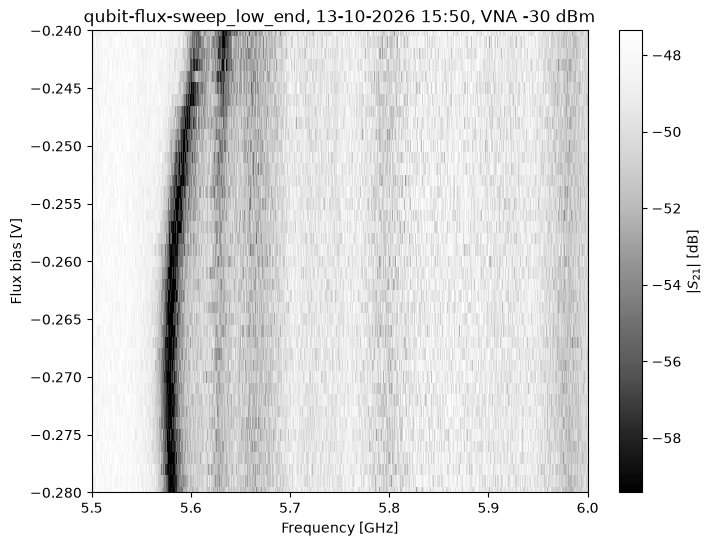

file        : 1791929069-qubit-flux-sweep_0-0_5V.json  (13-10-2026 16:04:29)
frequency   : 5.5000 - 7.0000 GHz  (1501 points)
flux bias   : 0 -> -0.5 V  (501 points)
VNA power   : -30.0 dBm, IF bw 1000.0 Hz, averages 1
attenuator  : 25.0 dB (warm programmable)


saved results\1791929069-qubit-flux-sweep_0-0_5V-s21-db.png


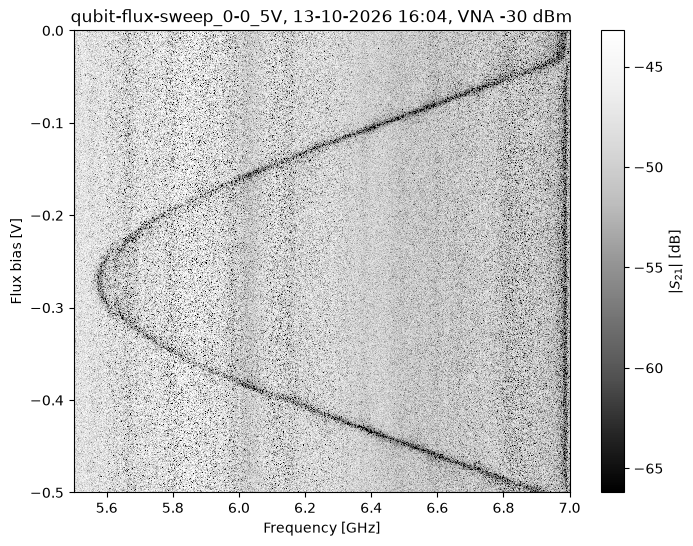

file        : 1791929955-qubit-flux-sweep_7ghz.json  (13-10-2026 16:19:15)
frequency   : 6.0000 - 8.0000 GHz  (2001 points)
flux bias   : 0.1 -> -0.1 V  (201 points)
VNA power   : -30.0 dBm, IF bw 1000.0 Hz, averages 2
attenuator  : 25.0 dB (warm programmable)


saved results\1791929955-qubit-flux-sweep_7ghz-s21-db.png


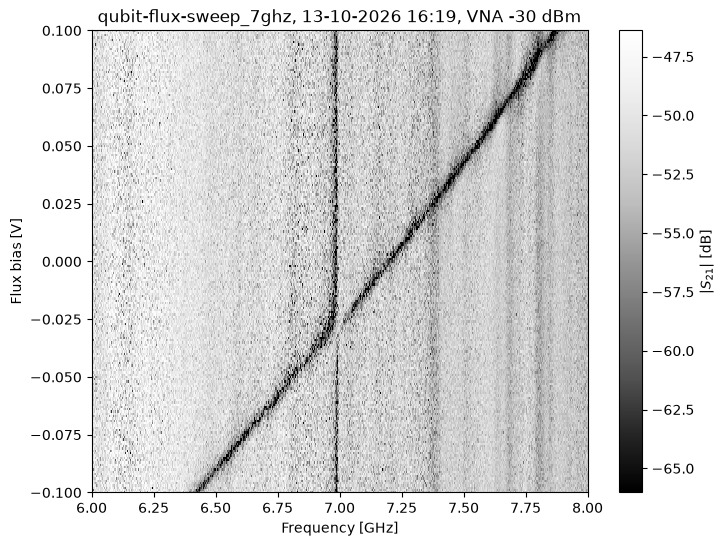

file        : 1791934219-qubit-flux-sweep_7ghz_lowpower.json  (13-10-2026 17:30:19)
frequency   : 6.0000 - 8.0000 GHz  (2001 points)
flux bias   : 0.1 -> -0.1 V  (41 points)
VNA power   : -40.0 dBm, IF bw 1000.0 Hz, averages 10
attenuator  : 25.0 dB (warm programmable)


saved results\1791934219-qubit-flux-sweep_7ghz_lowpower-s21-db.png


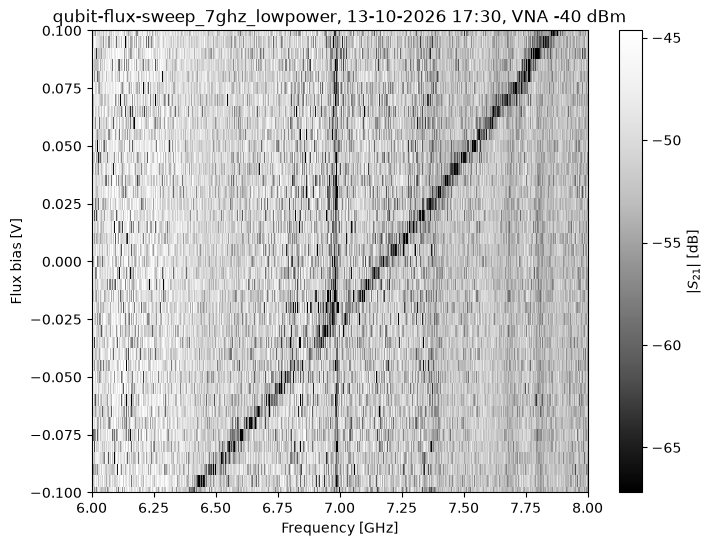

file        : 1791991735-qubit-flux-sweep_low_end_2.json  (14-10-2026 09:28:55)
frequency   : 5.5000 - 6.0000 GHz  (501 points)
flux bias   : -0.2 -> -0.35 V  (31 points)
VNA power   : -40.0 dBm, IF bw 100.0 Hz, averages 10
attenuator  : 25.0 dB (warm programmable)


saved results\1791991735-qubit-flux-sweep_low_end_2-s21-db.png


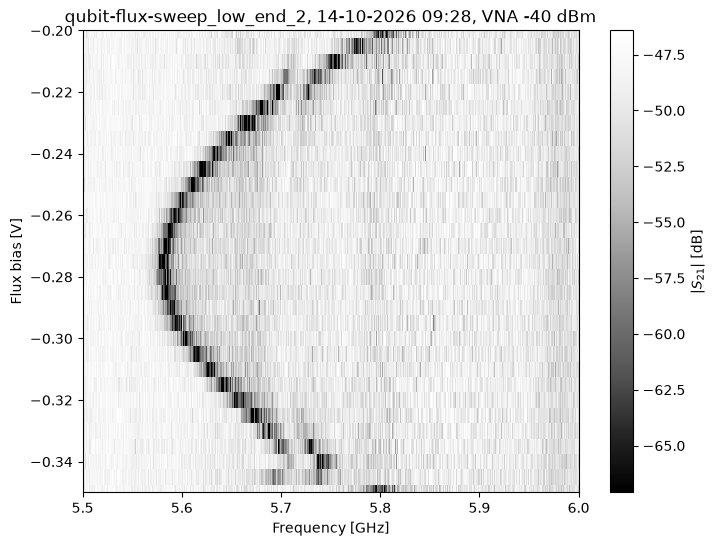

In [2]:
for data_file in FILES:
    s = qfs.load_sweep(data_file)
    print(qfs.summary(s))
    fig = qfs.plot_s21_map(s)
    fig.axes[0].set_title(qfs.title(s))
    save(fig, data_file, "s21-db")
    plt.show()

### 2. Transmon fit

The qubit frequency at each flux point is the minimum of $|S_{21}/S_\mathrm{bg}|$ (background: median over flux). These points are fitted to

$$f_{01}(V) = (f_\max + E_C)\left(\cos^2\varphi + d^2\sin^2\varphi\right)^{1/4} - E_C,\qquad \varphi = \pi\,\frac{V - V_0}{\text{period}},$$

with $E_C = 0.223$ GHz fixed from the anharmonicity of the 3-level power fit ($\alpha/2\pi = -223$ MHz).
The upper sweet spot $V_0$ lies outside the 0 to −0.5 V sweep, so the points of the 7 GHz sweep (`EXTRA`) are added to pin down $f_\max$; the figure shows only the main sweep.
Points more than 30 MHz off a first robust fit (anti-crossings near 5.6 and 7.0 GHz, noise) are left out of the final fit.

f_max   = 8.6366 +- 0.0108 GHz
d       = 0.4300 +- 0.0010 
v0      = 0.3688 +- 0.0023 V
period  = 1.2765 +- 0.0045 V
E_C     = 0.223 GHz (fixed)
f_min   = 5.5864 GHz at -0.2695 V
points  : 650 of 702 used, rms residual 9.5 MHz


saved results\1791929069-qubit-flux-sweep_0-0_5V-transmon-fit.png


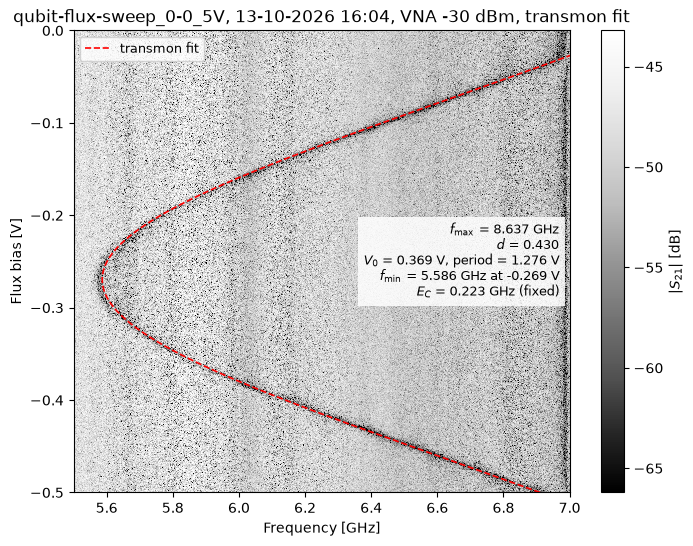

In [3]:
sweep = qfs.load_sweep(MAIN)
flux, f = qfs.find_qubit_dips(sweep)
for path in EXTRA:
    v, fe = qfs.find_qubit_dips(qfs.load_sweep(path))
    flux, f = np.concatenate([flux, v]), np.concatenate([f, fe])

fit = qfs.fit_transmon(flux, f)
print(fit.report())

fig = qfs.plot_fit(sweep, fit)
fig.axes[0].set_title(qfs.title(sweep) + ", transmon fit")
save(fig, MAIN, "transmon-fit")
plt.show()